In [24]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

In [25]:
square_side_length = 10
off_nadir_degrees = 10
distance = 10

Close widtH: 9.189795548777946
Far width: 10.966878266241855
Height: 10.233811499435838

Close height: 4.665781479009146
Far height: 5.568030020426691


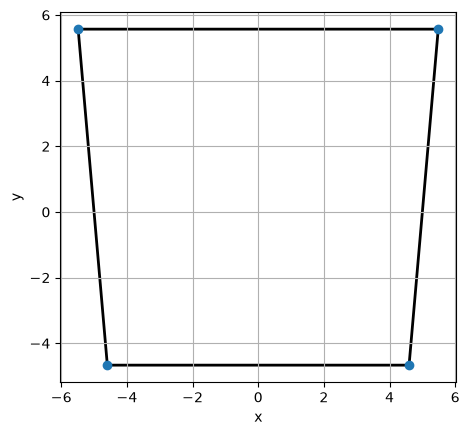

In [26]:
off_nadir_radians = math.radians(off_nadir_degrees)
S = square_side_length
d = distance
t = S / (2 * d)
theta = off_nadir_radians
alpha = math.atan(t)
c = math.cos(theta)
s = math.sin(theta)

w_near = 2 * d * c * t / (c + t * s)
w_far = 2 * d * c * t / (c - t * s)
x_near = d * t / (c + t * s)
x_far = d * t / (c - t * s)
x = x_near + x_far

print(f"Close widtH: {w_near}")
print(f"Far width: {w_far}")
print(f"Height: {x}")
print()
print(f"Close height: {x_near}")
print(f"Far height: {x_far}")


vertices = (
    (-(d * c * t) / (c + t * s),    -d * t / (c + t * s)),
    ((d * c * t) / (c + t * s),     -d * t / (c + t * s)),
    ((d * c * t) / (c - t * s),     (d * t) / (c - t * s)),
    (-(d * c * t) / (c - t * s),    (d * t) / (c - t * s)),
)

fig, ax = plt.subplots()

trapezoid = Polygon(
    vertices,
    closed=True,
    fill=False,
    linewidth=2
)

ax.add_patch(trapezoid)

# Plot vertices
x, y = zip(*vertices)
ax.scatter(x, y)

# Keep geometry visually accurate
ax.set_aspect("equal")
ax.autoscale_view()
ax.grid(True)

ax.set_xlabel("x")
ax.set_ylabel("y")

plt.show()